## 0. Setup

In [3]:
import os, time, math, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Dataset

import torchvision
from torchvision import datasets

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

# ---- GPU mode  ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | torchvision {torchvision.__version__} | device: {device}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    torch.backends.cudnn.benchmark = True
else:
    print("WARNING: no GPU found -> Runtime > Change runtime type > T4 GPU, then re-run. (CPU will be very slow.)")

os.makedirs("figures", exist_ok=True)

def sync():
    # GPU kernels are asynchronous: synchronize before reading the clock, otherwise timings are wrong
    if device.type == "cuda":
        torch.cuda.synchronize()

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device: cuda
GPU: Tesla T4


In [4]:
# ============================ CONFIGURATION ============================
QUICK_RUN      = False
USE_PRETRAINED = True
RUN_ABLATION   = True

CFG = dict(
    batch_size   = 128,
    val_size     = 5000,           # validation split taken from the 60k training images
    n_train      = None,           # None = use all remaining training images
    n_test       = None,           # None = full 10k test set

    # Part 1.1  CNN
    cnn_epochs = 12, cnn_lr = 0.01, cnn_momentum = 0.9, cnn_weight_decay = 1e-4, cnn_patience = 3,

    # Part 1.2  Faster R-CNN
    det_train_samples = 8000, det_val_samples = 1000, det_epochs = 2,
    det_batch = 16, det_img_size = 112, det_lr = 0.005,

    # Part 1.4  Transfer learning
    tl_mode = "classifier", tl_epochs = 3, tl_img_size = 64, tl_lr = 1e-4, tl_batch = 128,

    # Part 2  Vision Transformer
    vit_epochs = 15, vit_lr = 1e-3, vit_weight_decay = 1e-2, vit_patch = 4, vit_dim = 64,
    vit_heads = 4, vit_depth = 4, vit_mlp_ratio = 2, vit_dropout = 0.1, vit_patience = 5,
)

if QUICK_RUN:
    USE_PRETRAINED = False if not torch.cuda.is_available() else USE_PRETRAINED
    RUN_ABLATION = False
    CFG.update(val_size=512, n_train=2048, n_test=1000,
               cnn_epochs=1, det_train_samples=128, det_val_samples=64, det_epochs=1,
               tl_epochs=1, vit_epochs=1)
print("QUICK_RUN =", QUICK_RUN, "| USE_PRETRAINED =", USE_PRETRAINED)

QUICK_RUN = False | USE_PRETRAINED = True


## 1. Prepare the data (course life-cycle, step 1)
The whole of MNIST is tiny (≈ 190 MB as float32), so it is kept as tensors and each batch is moved to the GPU and
pre-processed **on the GPU** (resize, 3 channels, normalization). This is much faster than PIL transforms on Colab's 2 CPU cores.

Split: 55 000 train / 5 000 validation / 10 000 test. The **validation set drives early stopping and model selection**;
the **test set is only used once per model for the final numbers** (selecting on the test set would inflate the results).

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.73MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 136kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.28MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.82MB/s]


train 55000 | val 5000 | test 10000
class balance (train): [5424, 6188, 5441, 5610, 5378, 4946, 5449, 5755, 5320, 5489]


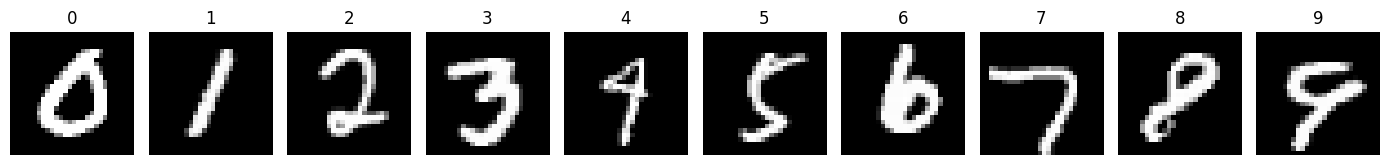

In [5]:
raw_train = datasets.MNIST(root="./data", train=True,  download=True)
raw_test  = datasets.MNIST(root="./data", train=False, download=True)

X_all  = raw_train.data.unsqueeze(1).float().div(255)
y_all  = raw_train.targets.long()
X_test = raw_test.data.unsqueeze(1).float().div(255)
y_test = raw_test.targets.long()

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_all), generator=g)
val_idx, train_idx = perm[:CFG["val_size"]], perm[CFG["val_size"]:]
if CFG["n_train"]: train_idx = train_idx[:CFG["n_train"]]

Xtr, ytr = X_all[train_idx], y_all[train_idx]
Xva, yva = X_all[val_idx],   y_all[val_idx]
if CFG["n_test"]:
    X_test, y_test = X_test[:CFG["n_test"]], y_test[:CFG["n_test"]]

train_set = TensorDataset(Xtr, ytr)
val_set   = TensorDataset(Xva, yva)
test_set  = TensorDataset(X_test, y_test)

bs = CFG["batch_size"]
train_dl = DataLoader(train_set, batch_size=bs, shuffle=True)
val_dl   = DataLoader(val_set,   batch_size=1000, shuffle=False)
test_dl  = DataLoader(test_set,  batch_size=1000, shuffle=False)

print(f"train {len(train_set)} | val {len(val_set)} | test {len(test_set)}")
print("class balance (train):", torch.bincount(ytr).tolist())

fig, axes = plt.subplots(1, 10, figsize=(14, 1.8))
for d, ax in enumerate(axes):
    ax.imshow(Xtr[(ytr == d).nonzero()[0, 0], 0], cmap="gray"); ax.set_title(str(d)); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Shared utilities

In [7]:
# ---------- GPU-side preprocessing ----------
MNIST_MEAN, MNIST_STD = 0.1307, 0.3081
def prep_mnist(x):
    return (x - MNIST_MEAN) / MNIST_STD

IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMNET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
def make_prep_imagenet(size):
    # MNIST is 1x28x28; ImageNet models expect 3 channels, larger images and ImageNet statistics
    def prep(x):
        x = F.interpolate(x, size=(size, size), mode="bilinear", align_corners=False)
        x = x.repeat(1, 3, 1, 1)
        return (x - IMNET_MEAN.to(x.device)) / IMNET_STD.to(x.device)
    return prep

def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))

# ---------- evaluation ----------
@torch.no_grad()
def evaluate(model, loader, prep, criterion=None):
    criterion = criterion or nn.CrossEntropyLoss()
    model.eval()
    preds, trues, total_loss, n = [], [], 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        out = model(prep(xb))
        total_loss += criterion(out, yb).item() * len(yb); n += len(yb)
        preds.append(out.argmax(1).cpu()); trues.append(yb.cpu())
    y_pred, y_true = torch.cat(preds).numpy(), torch.cat(trues).numpy()
    return dict(loss=total_loss / n, acc=accuracy_score(y_true, y_pred),
                f1=f1_score(y_true, y_pred, average="macro"), y_pred=y_pred, y_true=y_true)

def timed_evaluate(model, loader, prep):
    sync(); t0 = time.perf_counter()
    res = evaluate(model, loader, prep)
    sync(); return res, time.perf_counter() - t0

# ---------- training loop + early stopping  ----------
def fit(model, train_dl, val_dl, optimizer, prep, epochs, scheduler=None, patience=None, name="model"):
    criterion = nn.CrossEntropyLoss()
    hist = dict(train_loss=[], val_loss=[], train_acc=[], val_acc=[])
    best_val, best_state, bad = float("inf"), None, 0
    sync(); t0 = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        run_loss, correct, seen = 0.0, 0, 0
        for xb, yb in tqdm(train_dl, desc=f"{name} {epoch}/{epochs}", leave=False):
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            optimizer.zero_grad()                  # 1) clear gradients
            out = model(prep(xb))                  # 2) forward
            loss = criterion(out, yb)              # 3) loss
            loss.backward()                        # 4) backward (credit assignment)
            optimizer.step()                       # 5) update weights
            run_loss += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); seen += len(yb)
        if scheduler is not None:
            scheduler.step()
        val = evaluate(model, val_dl, prep, criterion)
        hist["train_loss"].append(run_loss / seen); hist["train_acc"].append(correct / seen)
        hist["val_loss"].append(val["loss"]);       hist["val_acc"].append(val["acc"])
        print(f"[{name}] epoch {epoch:2d}/{epochs} | train loss {run_loss/seen:.4f} acc {correct/seen:.4f} "
              f"| val loss {val['loss']:.4f} acc {val['acc']:.4f}")
        if val["loss"] < best_val - 1e-4:
            best_val, bad = val["loss"], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if patience and bad >= patience:
                print(f"[{name}] early stopping at epoch {epoch} (best val loss {best_val:.4f})"); break
    sync(); train_time = time.perf_counter() - t0
    if best_state is not None:
        model.load_state_dict(best_state)          # keep the best epoch, not the last one
    hist["epochs_run"] = epoch
    return hist, train_time

# ---------- results registry ----------
RESULTS = {}
def log_result(name, kind, model, metrics, train_time, epochs, infer_s, n_test, loss_kind="cross-entropy"):
    RESULTS[name] = {
        "Model": name, "Type": kind,
        "Params (M)": count_params(model) / 1e6, "Trainable (M)": count_params(model, True) / 1e6,
        "Accuracy (%)": 100 * metrics["acc"], "Macro-F1": metrics["f1"],
        "Test loss": metrics["loss"], "Loss type": loss_kind,
        "Train time (s)": train_time, "Train time / epoch (s)": train_time / max(1, epochs), "Epochs": epochs, "Inference (ms/img)": 1000 * infer_s / n_test,
    }

def results_df(names=None):
    df = pd.DataFrame([RESULTS[n] for n in (names or RESULTS)]).set_index("Model")
    return df

# ---------- plots ----------
def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["val_loss"], label="val")
    ax[0].set_title(f"{title} - loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["train_acc"], label="train"); ax[1].plot(h["val_acc"], label="val")
    ax[1].set_title(f"{title} - accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(f"figures/{title.replace(' ', '_')}_history.png", dpi=120); plt.show()

def plot_confusion(y_true, y_pred, title, labels=range(10)):
    cm = confusion_matrix(y_true, y_pred, labels=list(labels))
    fig, ax = plt.subplots(figsize=(5, 4.5))
    im = ax.imshow(cm, cmap="Blues"); plt.colorbar(im, ax=ax, fraction=0.046)
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{title} - confusion matrix")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                                 color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout(); plt.savefig(f"figures/{title.replace(' ', '_')}_confusion.png", dpi=120); plt.show()

def print_per_class_accuracy(y_true, y_pred):
    # same idea as the course's per-class accuracy loop on CIFAR-10
    for c in range(10):
        m = y_true == c
        print(f"Accuracy for class {c}: {100 * (y_pred[m] == c).mean():5.1f} %  ({m.sum()} images)")

# Part 1 — CNN classifier

## 1.1 Custom CNN (PyTorch, GPU)


In [8]:
def conv_out(n, f, p=0, s=1):
    return (n + 2 * p - f) // s + 1          # course formula 4.3.2

# Hyper-parameters explicitly chosen
K, PAD, STRIDE, POOL = 3, 1, 1, 2
print("28x28 --conv(3x3, p=1, s=1)--> ", conv_out(28, K, PAD, STRIDE), "x", conv_out(28, K, PAD, STRIDE))
print("28x28 --conv(3x3, p=0, s=1)--> ", conv_out(28, K, 0, 1), "x", conv_out(28, K, 0, 1), " (shrinks, corners under-used)")
print("28x28 --conv(3x3, p=1, s=2)--> ", conv_out(28, K, 1, 2), "x", conv_out(28, K, 1, 2), " (stride 2 = downsampling)")

# Why CNNs: parameter sharing
conv_params  = (K * K * 1 + 1) * 32
dense_params = (28 * 28) * (28 * 28 * 32) + 28 * 28 * 32        # dense layer producing the same 32x28x28 output
print(f"\nConv layer 1 -> 32 maps of 28x28 : {conv_params:,} parameters")
print(f"Dense layer giving the same shape : {dense_params:,} parameters  (x{dense_params // conv_params:,})")

28x28 --conv(3x3, p=1, s=1)-->  28 x 28
28x28 --conv(3x3, p=0, s=1)-->  26 x 26  (shrinks, corners under-used)
28x28 --conv(3x3, p=1, s=2)-->  14 x 14  (stride 2 = downsampling)

Conv layer 1 -> 32 maps of 28x28 : 320 parameters
Dense layer giving the same shape : 19,694,080 parameters  (x61,544)


In [9]:
class MNISTCNN(nn.Module):
    #   Conv32 -> ReLU -> Conv64 -> ReLU -> MaxPool -> Dropout(.25) -> Flatten -> Dense128 -> ReLU -> Dropout(.5) -> Dense10
    def __init__(self, k=3, padding=1, stride=1, c1=32, c2=64, pool=2,
                 p_drop1=0.25, p_drop2=0.5, hidden=128, n_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(1,  c1, k, stride=stride, padding=padding)
        self.conv2 = nn.Conv2d(c1, c2, k, stride=stride, padding=padding)
        self.pool  = nn.MaxPool2d(pool)
        self.drop1 = nn.Dropout(p_drop1)
        side = conv_out(conv_out(28, k, padding, stride), k, padding, stride) // pool   # size after conv-conv-pool
        self.fc1   = nn.Linear(c2 * side * side, hidden)
        self.drop2 = nn.Dropout(p_drop2)
        self.fc2   = nn.Linear(hidden, n_classes)
        # initialisation as in the course: Kaiming for ReLU layers, Xavier for the output layer
        for m in (self.conv1, self.conv2, self.fc1):
            nn.init.kaiming_uniform_(m.weight, nonlinearity="relu")
        nn.init.xavier_uniform_(self.fc2.weight)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = self.drop1(self.pool(x))
        x = torch.flatten(x, 1)
        x = self.drop2(F.relu(self.fc1(x)))
        return self.fc2(x)
cnn = MNISTCNN(k=K, padding=PAD, stride=STRIDE, pool=POOL).to(device)
print(cnn)
print(f"\nTotal parameters: {count_params(cnn):,}")

# shape trace with forward hooks
print("\nShape trace (batch of 1):")
hooks = [m.register_forward_hook(lambda m, i, o, n=n: print(f"  {n:6s} {tuple(i[0].shape[1:])} -> {tuple(o.shape[1:])}"))
         for n, m in cnn.named_children() if isinstance(m, (nn.Conv2d, nn.MaxPool2d, nn.Linear))]
cnn.eval()
with torch.no_grad(): cnn(torch.zeros(1, 1, 28, 28, device=device))
for h in hooks: h.remove()

MNISTCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop1): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=12544, out_features=128, bias=True)
  (drop2): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

Total parameters: 1,625,866

Shape trace (batch of 1):
  conv1  (1, 28, 28) -> (32, 28, 28)
  conv2  (32, 28, 28) -> (64, 28, 28)
  pool   (64, 28, 28) -> (64, 14, 14)
  fc1    (12544,) -> (128,)
  fc2    (128,) -> (10,)


CNN 1/12:   0%|          | 0/430 [00:00<?, ?it/s]

[CNN] epoch  1/12 | train loss 0.4069 acc 0.8752 | val loss 0.0798 acc 0.9764


CNN 2/12:   0%|          | 0/430 [00:00<?, ?it/s]

[CNN] epoch  2/12 | train loss 0.1643 acc 0.9499 | val loss 0.0589 acc 0.9808


CNN 3/12:   0%|          | 0/430 [00:00<?, ?it/s]

[CNN] epoch  3/12 | train loss 0.1269 acc 0.9617 | val loss 0.0485 acc 0.9844


... (10 outputs left out)

CNN 9/12:   0%|          | 0/430 [00:00<?, ?it/s]

[CNN] epoch  9/12 | train loss 0.0622 acc 0.9799 | val loss 0.0359 acc 0.9892


CNN 10/12:   0%|          | 0/430 [00:00<?, ?it/s]

[CNN] epoch 10/12 | train loss 0.0585 acc 0.9814 | val loss 0.0398 acc 0.9886
[CNN] early stopping at epoch 10 (best val loss 0.0353)

Training time: 38.4 s


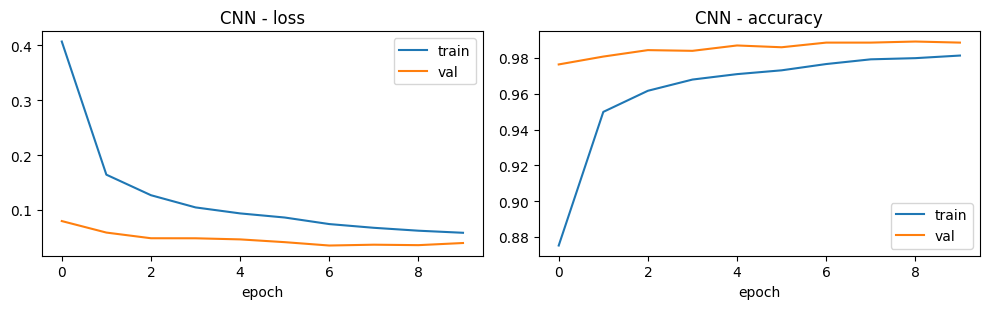

In [10]:
set_seed()
cnn = MNISTCNN(k=K, padding=PAD, stride=STRIDE, pool=POOL).to(device)
optimizer = torch.optim.SGD(cnn.parameters(), lr=CFG["cnn_lr"], momentum=CFG["cnn_momentum"],
                            weight_decay=CFG["cnn_weight_decay"])
hist_cnn, t_cnn = fit(cnn, train_dl, val_dl, optimizer, prep_mnist, CFG["cnn_epochs"],
                      patience=CFG["cnn_patience"], name="CNN")
print(f"\nTraining time: {t_cnn:.1f} s")
plot_history(hist_cnn, "CNN")

CNN | test loss 0.0320 | accuracy 98.94 % | macro-F1 0.9893
Accuracy for class 0:  99.5 %  (980 images)
Accuracy for class 1:  99.6 %  (1135 images)
Accuracy for class 2:  99.6 %  (1032 images)
Accuracy for class 3:  99.2 %  (1010 images)
Accuracy for class 4:  99.1 %  (982 images)
Accuracy for class 5:  98.8 %  (892 images)
Accuracy for class 6:  99.1 %  (958 images)
Accuracy for class 7:  98.6 %  (1028 images)
Accuracy for class 8:  98.8 %  (974 images)
Accuracy for class 9:  97.1 %  (1009 images)


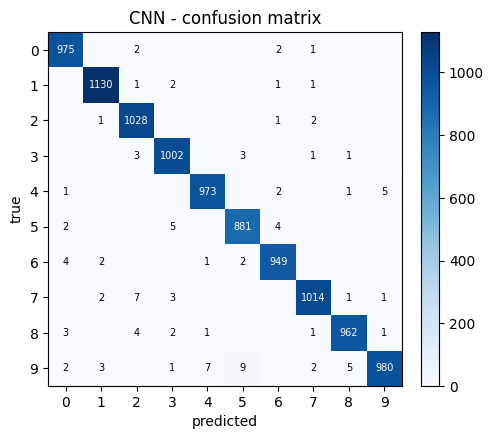

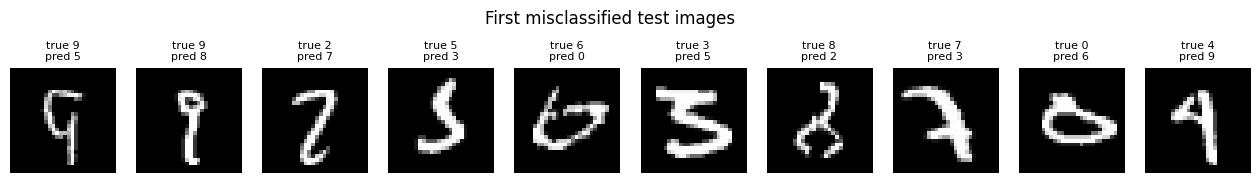

In [11]:
# Evaluate on the test set
res_cnn, t_inf = timed_evaluate(cnn, test_dl, prep_mnist)
print(f"CNN | test loss {res_cnn['loss']:.4f} | accuracy {100*res_cnn['acc']:.2f} % | macro-F1 {res_cnn['f1']:.4f}")
log_result("CNN (from scratch)", "Classifier", cnn, res_cnn, t_cnn, hist_cnn["epochs_run"], t_inf, len(test_set))
print_per_class_accuracy(res_cnn["y_true"], res_cnn["y_pred"])
plot_confusion(res_cnn["y_true"], res_cnn["y_pred"], "CNN")

# Make a few predictions  and show the mistakes
wrong = np.where(res_cnn["y_pred"] != res_cnn["y_true"])[0][:10]
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(1.6 * len(wrong), 2))
    for ax, i in zip(np.atleast_1d(axes), wrong):
        ax.imshow(X_test[i, 0], cmap="gray"); ax.axis("off")
        ax.set_title(f"true {res_cnn['y_true'][i]}\npred {res_cnn['y_pred'][i]}", fontsize=8)
    plt.suptitle("First misclassified test images", y=1.05); plt.show()

### effect of optimizer and regularization (validation set only)


In [12]:
if RUN_ABLATION:
    configs = {
        "SGD (no momentum)":     lambda p: torch.optim.SGD(p, lr=0.01),
        "SGD + momentum 0.9":    lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9),
        "Adam (lr 1e-3)":        lambda p: torch.optim.Adam(p, lr=1e-3),
        "Adam + L2 (wd 1e-4)":   lambda p: torch.optim.Adam(p, lr=1e-3, weight_decay=1e-4),
    }
    rows = []
    for name, make_opt in configs.items():
        set_seed()
        m = MNISTCNN(k=K, padding=PAD, stride=STRIDE, pool=POOL).to(device)
        h, t = fit(m, train_dl, val_dl, make_opt(m.parameters()), prep_mnist, 3, name=name[:12])
        rows.append({"Config": name, "Val loss": h["val_loss"][-1], "Val acc (%)": 100 * h["val_acc"][-1], "Time (s)": t})
    display(pd.DataFrame(rows).set_index("Config").round(4))
else:
    print("RUN_ABLATION = False -> skipped")

SGD (no mome 1/3:   0%|          | 0/430 [00:00<?, ?it/s]

[SGD (no mome] epoch  1/3 | train loss 0.6165 acc 0.8065 | val loss 0.1707 acc 0.9500


SGD (no mome 2/3:   0%|          | 0/430 [00:00<?, ?it/s]

[SGD (no mome] epoch  2/3 | train loss 0.2612 acc 0.9230 | val loss 0.1117 acc 0.9676


SGD (no mome 3/3:   0%|          | 0/430 [00:00<?, ?it/s]

[SGD (no mome] epoch  3/3 | train loss 0.1881 acc 0.9454 | val loss 0.0870 acc 0.9744


... (15 outputs left out)

[Adam + L2 (w] epoch  2/3 | train loss 0.1760 acc 0.9460 | val loss 0.0521 acc 0.9834


Adam + L2 (w 3/3:   0%|          | 0/430 [00:00<?, ?it/s]

[Adam + L2 (w] epoch  3/3 | train loss 0.1183 acc 0.9641 | val loss 0.0433 acc 0.9860


,Val loss,Val acc (%),Time (s)
Config,,,
SGD (no momentum),0.0870,97.44,10.5957
SGD + momentum 0.9,0.0547,98.28,10.7720
Adam (lr 1e-3),0.0445,98.60,11.2091
Adam + L2 (wd 1e-4),0.0433,98.60,11.1882


## 1.2 Faster R-CNN

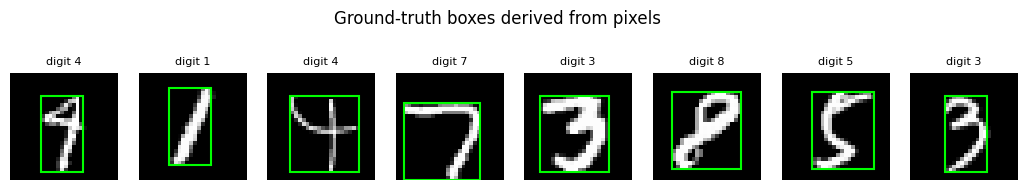

detection train/val/test: 8000 / 1000 / 10000 images


In [13]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou

def digit_box(img, thr=0.2):
    # tight box [x1, y1, x2, y2] around the pixels > thr of a (1, 28, 28) image
    mask = img[0] > thr
    cols = torch.where(mask.any(0))[0]; rows = torch.where(mask.any(1))[0]
    if len(cols) == 0 or len(rows) == 0:
        return torch.tensor([0., 0., 28., 28.])
    return torch.tensor([cols.min(), rows.min(), cols.max() + 1, rows.max() + 1], dtype=torch.float32)

class MNISTDetection(Dataset):
    # Same Dataset pattern as the course (__len__ / __getitem__), but returns (image, target dict) as torchvision detectors expect
    def __init__(self, X, y):
        self.X, self.y = X, y
        self.boxes = [digit_box(x) for x in X]
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        target = {"boxes": self.boxes[i].unsqueeze(0), "labels": torch.tensor([int(self.y[i]) + 1])}  # 0 = background
        return self.X[i].repeat(3, 1, 1), target              # detectors expect 3-channel images in [0, 1]

def det_collate(batch):
    return tuple(zip(*batch))

n_tr, n_va = CFG["det_train_samples"], CFG["det_val_samples"]
det_train = MNISTDetection(Xtr[:n_tr], ytr[:n_tr])
det_val   = MNISTDetection(Xva[:n_va], yva[:n_va])
det_test  = MNISTDetection(X_test, y_test)                    # same test images as every other model
det_train_dl = DataLoader(det_train, batch_size=CFG["det_batch"], shuffle=True,  collate_fn=det_collate)
det_val_dl   = DataLoader(det_val,   batch_size=32, shuffle=False, collate_fn=det_collate)
det_test_dl  = DataLoader(det_test,  batch_size=32, shuffle=False, collate_fn=det_collate)

# sanity check of the derived boxes
fig, axes = plt.subplots(1, 8, figsize=(13, 2))
for ax, i in zip(axes, range(8)):
    img, tgt = det_train[i]
    ax.imshow(img[0], cmap="gray"); ax.axis("off")
    x1, y1, x2, y2 = tgt["boxes"][0].tolist()
    ax.add_patch(plt.Rectangle((x1 - 0.5, y1 - 0.5), x2 - x1, y2 - y1, fill=False, edgecolor="lime", lw=1.5))
    ax.set_title(f"digit {tgt['labels'][0].item() - 1}", fontsize=8)
plt.suptitle("Ground-truth boxes derived from pixels", y=1.08); plt.show()
print(f"detection train/val/test: {len(det_train)} / {len(det_val)} / {len(det_test)} images")

In [15]:
def build_faster_rcnn(num_classes=11, img_size=112):
    weights = FasterRCNN_ResNet50_FPN_Weights.COCO_V1 if USE_PRETRAINED else None
    # min_size = max_size = img_size: the 28x28 digit is up-scaled x4 inside the detector
    model = fasterrcnn_resnet50_fpn(weights=weights, weights_backbone=None, min_size=img_size, max_size=img_size)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)   # 10 digits + background
    return model

@torch.no_grad()
def detector_loss(model, loader):
    model.train(); total, n = 0.0, 0
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm): m.eval()
    for imgs, tgts in loader:
        imgs = [im.to(device) for im in imgs]; tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
        total += sum(model(imgs, tgts).values()).item() * len(imgs); n += len(imgs)
    return total / n

@torch.no_grad()
def eval_detector(model, loader):
    model.eval(); preds, trues, ious = [], [], []
    for imgs, tgts in loader:
        outs = model([im.to(device) for im in imgs])
        for o, t in zip(outs, tgts):
            trues.append(int(t["labels"][0]) - 1)
            if len(o["scores"]) == 0:
                preds.append(-1); ious.append(0.0)                 # nothing detected -> counted as an error
            else:
                j = int(o["scores"].argmax())
                preds.append(int(o["labels"][j]) - 1)
                ious.append(box_iou(o["boxes"][j:j + 1].cpu(), t["boxes"]).item())
    preds, trues = np.array(preds), np.array(trues)
    return dict(acc=(preds == trues).mean(), f1=f1_score(trues, preds, labels=list(range(10)), average="macro", zero_division=0),
                miou=float(np.mean(ious)), n_missed=int((preds == -1).sum()), y_pred=preds, y_true=trues)

set_seed()
frcnn = build_faster_rcnn(img_size=CFG["det_img_size"]).to(device)
print(f"Faster R-CNN parameters: {count_params(frcnn):,}  (pretrained COCO: {USE_PRETRAINED})")

Faster R-CNN parameters: 41,345,286  (pretrained COCO: True)


In [16]:
params = [p for p in frcnn.parameters() if p.requires_grad]
opt_det = torch.optim.SGD(params, lr=CFG["det_lr"], momentum=0.9, weight_decay=5e-4)       # course optimizer: SGD + momentum
warmup_iters = max(1, min(100, len(det_train_dl) - 1))
warmup = torch.optim.lr_scheduler.LinearLR(opt_det, start_factor=0.01, total_iters=warmup_iters)
epoch_sched = torch.optim.lr_scheduler.MultiStepLR(opt_det, milestones=[CFG["det_epochs"] - 1] if CFG["det_epochs"] > 1 else [], gamma=0.1)

hist_det = dict(train_loss=[], val_loss=[], train_acc=[], val_acc=[])
sync(); t0 = time.perf_counter()
for epoch in range(1, CFG["det_epochs"] + 1):
    frcnn.train(); run, seen = 0.0, 0
    for i, (imgs, tgts) in enumerate(tqdm(det_train_dl, desc=f"Faster R-CNN {epoch}/{CFG['det_epochs']}", leave=False)):
        imgs = [im.to(device) for im in imgs]; tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
        loss_dict = frcnn(imgs, tgts)
        loss = sum(loss_dict.values())
        opt_det.zero_grad(); loss.backward(); opt_det.step()
        if epoch == 1 and i < warmup_iters: warmup.step()          # linear warm-up during the first iterations
        run += loss.item() * len(imgs); seen += len(imgs)
    epoch_sched.step()
    v = eval_detector(frcnn, det_val_dl); vl = detector_loss(frcnn, det_val_dl)
    hist_det["train_loss"].append(run / seen); hist_det["val_loss"].append(vl); hist_det["val_acc"].append(v["acc"])
    hist_det["train_acc"].append(float("nan"))
    print(f"[Faster R-CNN] epoch {epoch}/{CFG['det_epochs']} | train loss {run/seen:.4f} | val loss {vl:.4f} | val acc {v['acc']:.4f} | mean IoU {v['miou']:.3f}")
sync(); t_det = time.perf_counter() - t0
print(f"\nTraining time: {t_det:.1f} s")

Faster R-CNN 1/2:   0%|          | 0/500 [00:00<?, ?it/s]

[Faster R-CNN] epoch 1/2 | train loss 0.1848 | val loss 0.0624 | val acc 0.9770 | mean IoU 0.918


Faster R-CNN 2/2:   0%|          | 0/500 [00:00<?, ?it/s]

[Faster R-CNN] epoch 2/2 | train loss 0.0442 | val loss 0.0464 | val acc 0.9840 | mean IoU 0.941

Training time: 502.4 s


Faster R-CNN | detection loss 0.0441 | accuracy 98.51 % | macro-F1 0.9851 | mean IoU of best box 0.943 | images with no detection: 0


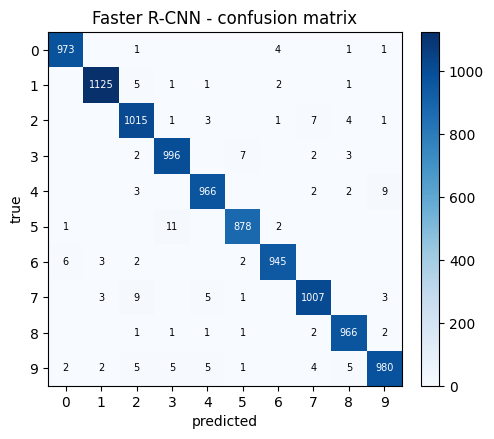

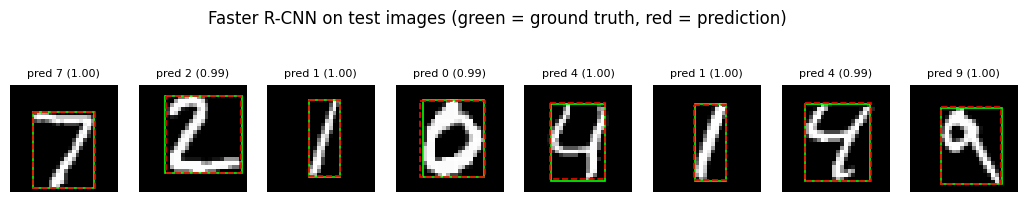

In [17]:
sync(); t0 = time.perf_counter()
res_det = eval_detector(frcnn, det_test_dl)
sync(); t_det_inf = time.perf_counter() - t0
test_det_loss = detector_loss(frcnn, det_test_dl)

print(f"Faster R-CNN | detection loss {test_det_loss:.4f} | accuracy {100*res_det['acc']:.2f} % | macro-F1 {res_det['f1']:.4f} "
      f"| mean IoU of best box {res_det['miou']:.3f} | images with no detection: {res_det['n_missed']}")
res_det["loss"] = test_det_loss
log_result("Faster R-CNN", "Detector", frcnn, res_det, t_det, CFG["det_epochs"], t_det_inf, len(det_test),
           loss_kind="detection (sum of 4 losses)")
plot_confusion(res_det["y_true"], res_det["y_pred"], "Faster R-CNN")   # images with no detection (-1) are left out of the matrix

# Visual check: predicted (red) vs ground-truth (green) boxes
frcnn.eval()
fig, axes = plt.subplots(1, 8, figsize=(13, 2.2))
with torch.no_grad():
    for ax, i in zip(axes, range(8)):
        img, tgt = det_test[i]
        o = frcnn([img.to(device)])[0]
        ax.imshow(img[0], cmap="gray"); ax.axis("off")
        x1, y1, x2, y2 = tgt["boxes"][0].tolist()
        ax.add_patch(plt.Rectangle((x1 - .5, y1 - .5), x2 - x1, y2 - y1, fill=False, edgecolor="lime", lw=1.2))
        if len(o["scores"]):
            j = int(o["scores"].argmax()); bx = o["boxes"][j].cpu().tolist()
            ax.add_patch(plt.Rectangle((bx[0] - .5, bx[1] - .5), bx[2] - bx[0], bx[3] - bx[1], fill=False, edgecolor="red", lw=1.2, ls="--"))
            ax.set_title(f"pred {o['labels'][j].item()-1} ({o['scores'][j]:.2f})", fontsize=8)
        else:
            ax.set_title("no detection", fontsize=8)
plt.suptitle("Faster R-CNN on test images (green = ground truth, red = prediction)", y=1.08); plt.show()

## 1.3 Comparison: CNN vs. Faster R-CNN

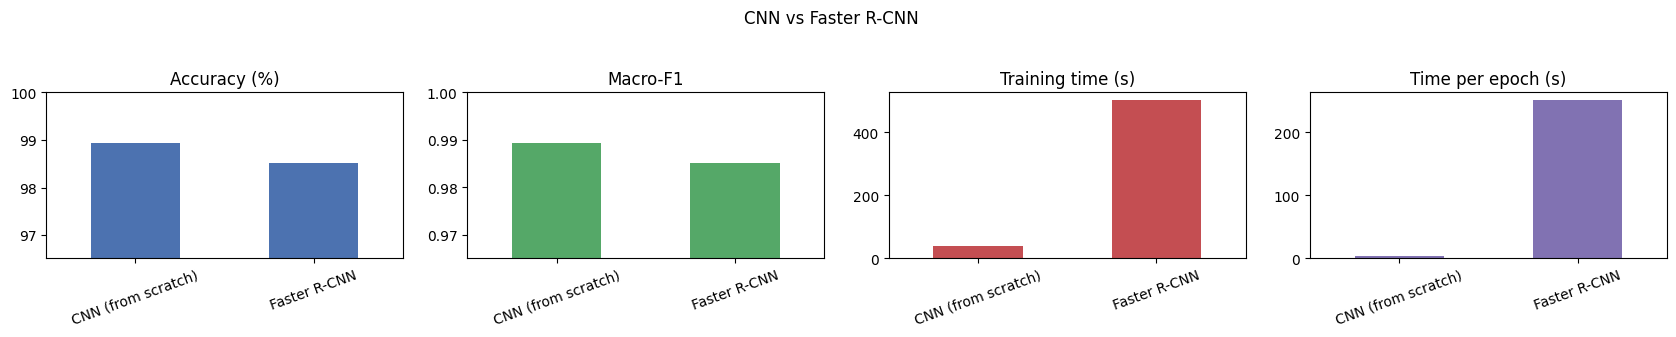

,Type,Params (M),Trainable (M),Accuracy (%),Macro-F1,Test loss,Loss type,Train time (s),Train time / epoch (s),Epochs,Inference (ms/img)
Model,,,,,,,,,,,
CNN (from scratch),Classifier,1.6259,1.6259,98.94,0.9893,0.0320,cross-entropy,38.3598,3.8360,10,0.0310
Faster R-CNN,Detector,41.3453,41.1229,98.51,0.9851,0.0441,detection (sum of 4 losses),502.4213,251.2106,2,11.5481


In [18]:
def compare_plot(names, title, fname):
    df = results_df(names)
    fig, ax = plt.subplots(1, 4, figsize=(17, 3.2))
    df["Accuracy (%)"].plot.bar(ax=ax[0], color="#4c72b0", rot=20); ax[0].set_title("Accuracy (%)")
    lo = max(0, df["Accuracy (%)"].min() - 2); ax[0].set_ylim(lo, 100)
    df["Macro-F1"].plot.bar(ax=ax[1], color="#55a868", rot=20); ax[1].set_title("Macro-F1")
    ax[1].set_ylim(max(0, df["Macro-F1"].min() - 0.02), 1.0)
    df["Train time (s)"].plot.bar(ax=ax[2], color="#c44e52", rot=20); ax[2].set_title("Training time (s)")
    df["Train time / epoch (s)"].plot.bar(ax=ax[3], color="#8172b2", rot=20); ax[3].set_title("Time per epoch (s)")
    for a in ax: a.set_xlabel("")
    plt.suptitle(title, y=1.04); plt.tight_layout(); plt.savefig(f"figures/{fname}.png", dpi=120, bbox_inches="tight"); plt.show()
    return df

df_13 = compare_plot(["CNN (from scratch)", "Faster R-CNN"], "CNN vs Faster R-CNN", "cnn_vs_frcnn")
display(df_13.round(4))

## 1.4 Fine-tuning pretrained models: AlexNet and VGG16

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 192MB/s]



=== AlexNet (classifier) | total 57.0 M params, trainable 54.6 M ===


AlexNet 1/3:   0%|          | 0/430 [00:00<?, ?it/s]

[AlexNet] epoch  1/3 | train loss 0.3671 acc 0.8787 | val loss 0.2001 acc 0.9344


AlexNet 2/3:   0%|          | 0/430 [00:00<?, ?it/s]

[AlexNet] epoch  2/3 | train loss 0.2182 acc 0.9267 | val loss 0.1567 acc 0.9502


AlexNet 3/3:   0%|          | 0/430 [00:00<?, ?it/s]

[AlexNet] epoch  3/3 | train loss 0.1838 acc 0.9394 | val loss 0.1739 acc 0.9420
AlexNet | test loss 0.1395 | accuracy 95.36 % | macro-F1 0.9528 | train 42.1 s


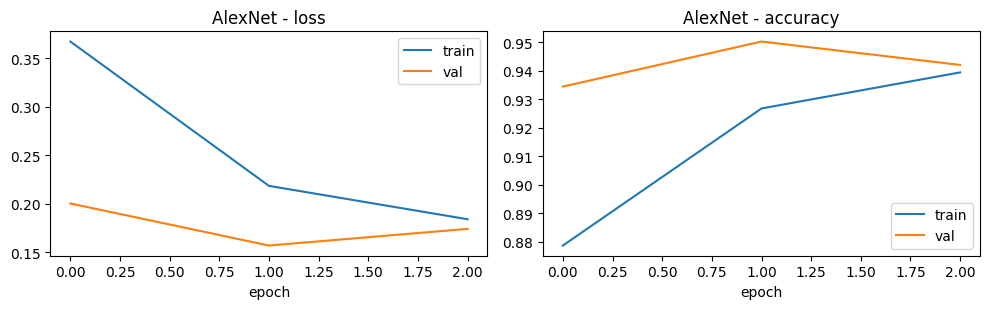

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 83.2MB/s]



=== VGG16 (classifier) | total 134.3 M params, trainable 119.6 M ===


VGG16 1/3:   0%|          | 0/430 [00:00<?, ?it/s]

[VGG16] epoch  1/3 | train loss 0.2614 acc 0.9151 | val loss 0.1361 acc 0.9560


VGG16 2/3:   0%|          | 0/430 [00:00<?, ?it/s]

[VGG16] epoch  2/3 | train loss 0.1144 acc 0.9630 | val loss 0.0905 acc 0.9710


VGG16 3/3:   0%|          | 0/430 [00:00<?, ?it/s]

[VGG16] epoch  3/3 | train loss 0.0941 acc 0.9693 | val loss 0.0838 acc 0.9738
VGG16 | test loss 0.0888 | accuracy 97.11 % | macro-F1 0.9709 | train 164.6 s


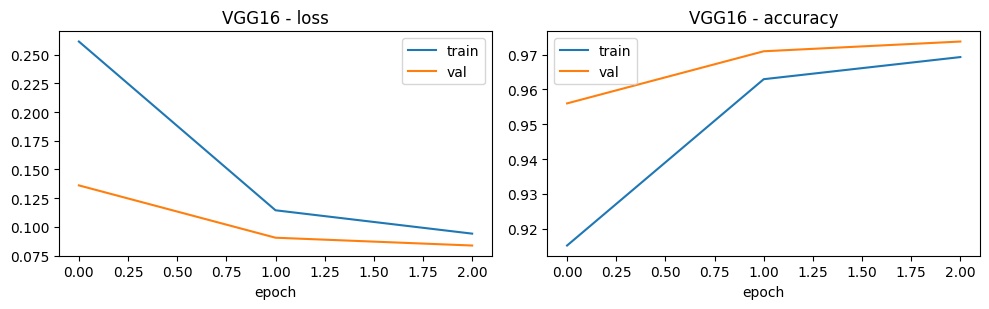

In [19]:
from torchvision.models import alexnet, vgg16, AlexNet_Weights, VGG16_Weights

def build_transfer(name, mode="classifier"):
    if name == "AlexNet":
        m = alexnet(weights=AlexNet_Weights.IMAGENET1K_V1 if USE_PRETRAINED else None)
    elif name == "VGG16":
        m = vgg16(weights=VGG16_Weights.IMAGENET1K_V1 if USE_PRETRAINED else None)
    else:
        raise ValueError(name)
    if mode == "classifier":
        for p in m.features.parameters():          # freeze the convolutional feature extractor
            p.requires_grad = False
    in_f = m.classifier[-1].in_features            # 4096
    m.classifier[-1] = nn.Linear(in_f, 10)         # new output layer: 10 digits
    return m

prep_tl = make_prep_imagenet(CFG["tl_img_size"])
tl_train_dl = DataLoader(train_set, batch_size=CFG["tl_batch"], shuffle=True)
transfer_hist = {}

for tl_name in ["AlexNet", "VGG16"]:
    set_seed()
    model = build_transfer(tl_name, CFG["tl_mode"]).to(device)
    lr = CFG["tl_lr"] if CFG["tl_mode"] == "classifier" else CFG["tl_lr"] / 10
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    print(f"\n=== {tl_name} ({CFG['tl_mode']}) | total {count_params(model)/1e6:.1f} M params, trainable {count_params(model, True)/1e6:.1f} M ===")
    h, t = fit(model, tl_train_dl, val_dl, opt, prep_tl, CFG["tl_epochs"], name=tl_name)
    res, t_inf = timed_evaluate(model, test_dl, prep_tl)
    print(f"{tl_name} | test loss {res['loss']:.4f} | accuracy {100*res['acc']:.2f} % | macro-F1 {res['f1']:.4f} | train {t:.1f} s")
    log_result(f"{tl_name} (fine-tuned)", "Transfer learning", model, res, t, h["epochs_run"], t_inf, len(test_set))
    plot_history(h, f"{tl_name}")
    transfer_hist[tl_name] = (h, res)
    del model, opt
    if device.type == "cuda": torch.cuda.empty_cache()

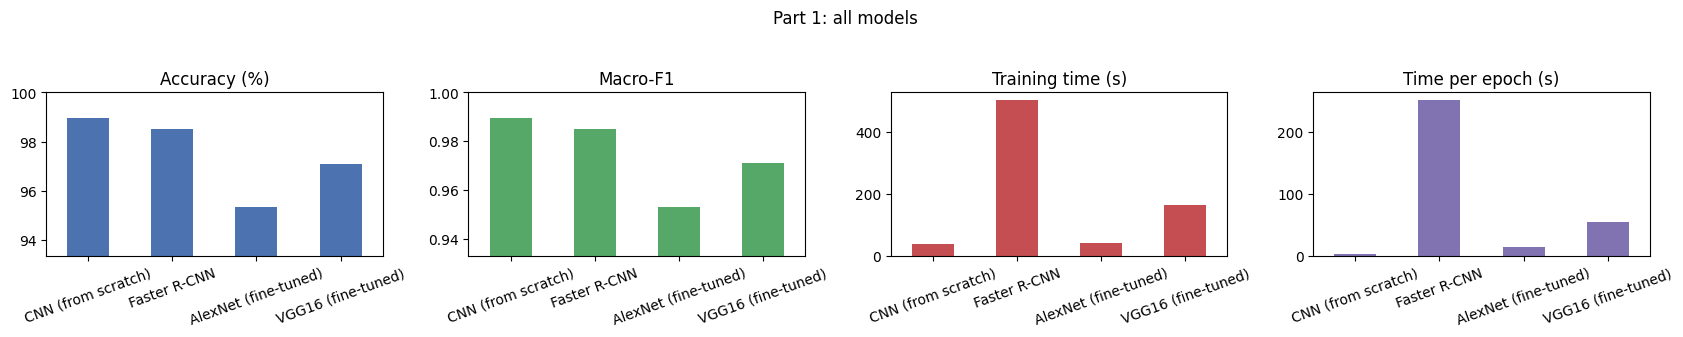

,Type,Params (M),Trainable (M),Accuracy (%),Macro-F1,Test loss,Loss type,Train time (s),Train time / epoch (s),Epochs,Inference (ms/img)
Model,,,,,,,,,,,
CNN (from scratch),Classifier,1.6259,1.6259,98.94,0.9893,0.0320,cross-entropy,38.3598,3.8360,10,0.0310
Faster R-CNN,Detector,41.3453,41.1229,98.51,0.9851,0.0441,detection (sum of 4 losses),502.4213,251.2106,2,11.5481
AlexNet (fine-tuned),Transfer learning,57.0448,54.5751,95.36,0.9528,0.1395,cross-entropy,42.0523,14.0174,3,0.0729
VGG16 (fine-tuned),Transfer learning,134.3015,119.5868,97.11,0.9709,0.0888,cross-entropy,164.5693,54.8564,3,0.4942


In [20]:
names_14 = ["CNN (from scratch)", "Faster R-CNN", "AlexNet (fine-tuned)", "VGG16 (fine-tuned)"]
df_14 = compare_plot(names_14, "Part 1: all models", "part1_all_models")
display(df_14.round(4))

# Part 2 — Vision Transformer (ViT) from scratch


one image: (1, 1, 28, 28) -> patches: (1, 49, 16) (batch, n_patches, patch_dim)


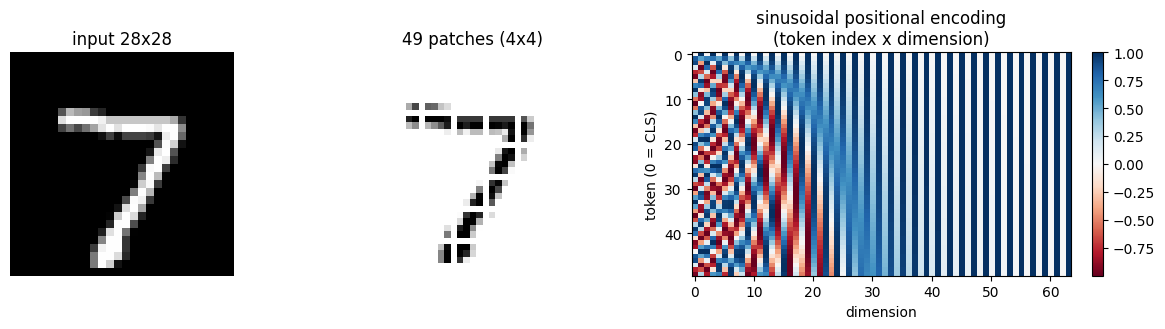

In [21]:
def patchify(x, p):
    # (B, C, H, W) -> (B, N, C*p*p): non-overlapping p x p patches, row-major order
    return F.unfold(x, kernel_size=p, stride=p).transpose(1, 2)

def positional_encoding(seq_len, d, n=10000.0):
    # Course 6.2.1:  P(k,2i) = sin(k / n^(2i/d)),  P(k,2i+1) = cos(k / n^(2i/d))
    assert d % 2 == 0
    k = torch.arange(seq_len, dtype=torch.float32).unsqueeze(1)           # positions (L, 1)
    div = torch.pow(n, torch.arange(0, d, 2, dtype=torch.float32) / d)    # n^(2i/d)   (d/2,)
    pe = torch.zeros(seq_len, d)
    pe[:, 0::2] = torch.sin(k / div); pe[:, 1::2] = torch.cos(k / div)
    return pe

# --- look at the two building blocks ---
x_demo = X_test[:1]
patches = patchify(x_demo, CFG["vit_patch"])
print("one image:", tuple(x_demo.shape), "-> patches:", tuple(patches.shape), "(batch, n_patches, patch_dim)")

g_ = 28 // CFG["vit_patch"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1, 1.2, 1.6]})
axes[0].imshow(x_demo[0, 0], cmap="gray"); axes[0].set_title("input 28x28"); axes[0].axis("off")
canvas = np.ones((g_ * (CFG["vit_patch"] + 1), g_ * (CFG["vit_patch"] + 1)))
for idx in range(patches.shape[1]):
    r, c = divmod(idx, g_); p_ = CFG["vit_patch"]
    canvas[r * (p_ + 1): r * (p_ + 1) + p_, c * (p_ + 1): c * (p_ + 1) + p_] = 1 - patches[0, idx].reshape(p_, p_).numpy()
axes[1].imshow(canvas, cmap="gray", vmin=0, vmax=1); axes[1].set_title(f"{patches.shape[1]} patches ({p_}x{p_})"); axes[1].axis("off")
pe = positional_encoding(patches.shape[1] + 1, CFG["vit_dim"])
im = axes[2].imshow(pe.numpy(), aspect="auto", cmap="RdBu"); axes[2].set_title("sinusoidal positional encoding\n(token index x dimension)")
axes[2].set_xlabel("dimension"); axes[2].set_ylabel("token (0 = CLS)"); plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout(); plt.show()

In [22]:
class MultiHeadSelfAttention(nn.Module):
    # Course 6.2.2: Q = X W_Q, K = X W_K, V = X W_V ; Attention = softmax(Q K^T / sqrt(d_k)) V ; heads are concatenated then projected
    def __init__(self, d, heads):
        super().__init__()
        assert d % heads == 0
        self.h, self.dk = heads, d // heads
        self.qkv = nn.Linear(d, 3 * d)       # W_Q, W_K, W_V for all heads in a single matmul
        self.out = nn.Linear(d, d)           # W_O applied on the concatenation of the heads
        self.store_attn, self.last_attn = False, None

    def forward(self, x):
        B, N, D = x.shape
        q, k, v = self.qkv(x).view(B, N, 3, self.h, self.dk).permute(2, 0, 3, 1, 4)    # each (B, h, N, d_k)
        attn = (q @ k.transpose(-2, -1) / math.sqrt(self.dk)).softmax(dim=-1)           # (B, h, N, N)
        if self.store_attn: self.last_attn = attn.detach()
        out = (attn @ v).transpose(1, 2).reshape(B, N, D)                               # concat heads
        return self.out(out)

class ViTBlock(nn.Module):
    # Add & Norm (course 6.2.3): residual connection + LayerNorm, then a position-wise feed-forward network
    def __init__(self, d, heads, mlp_ratio, dropout):
        super().__init__()
        self.norm1, self.attn = nn.LayerNorm(d), MultiHeadSelfAttention(d, heads)
        self.norm2 = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(d, d * mlp_ratio), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(d * mlp_ratio, d), nn.Dropout(dropout))
    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x

class ViT(nn.Module):
    def __init__(self, img=28, patch=7, in_ch=1, d=64, heads=4, depth=4, mlp_ratio=2, dropout=0.1, n_classes=10):
        super().__init__()
        assert img % patch == 0
        self.patch, self.n_patches = patch, (img // patch) ** 2
        self.embed = nn.Linear(in_ch * patch * patch, d)                     # linear patch embedding
        self.cls = nn.Parameter(torch.zeros(1, 1, d)); nn.init.normal_(self.cls, std=0.02)   # learnable [CLS] token
        self.register_buffer("pos", positional_encoding(self.n_patches + 1, d).unsqueeze(0))  # fixed sin/cos encoding
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([ViTBlock(d, heads, mlp_ratio, dropout) for _ in range(depth)])
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, n_classes)                                  # raw logits

    def forward(self, x):
        t = self.embed(patchify(x, self.patch))                              # (B, N, d)
        t = torch.cat([self.cls.expand(t.shape[0], -1, -1), t], dim=1) + self.pos
        t = self.drop(t)
        for blk in self.blocks:
            t = blk(t)
        return self.head(self.norm(t[:, 0]))                                 # classify from the [CLS] token

def make_vit():
    return ViT(patch=CFG["vit_patch"], d=CFG["vit_dim"], heads=CFG["vit_heads"], depth=CFG["vit_depth"],
               mlp_ratio=CFG["vit_mlp_ratio"], dropout=CFG["vit_dropout"])

set_seed()
vit = make_vit().to(device)
print(f"ViT parameters: {count_params(vit):,}")
with torch.no_grad():
    print("forward check:", tuple(vit(prep_mnist(X_test[:4].to(device))).shape), "(expected (4, 10))")

ViT parameters: 135,818
forward check: (4, 10) (expected (4, 10))


ViT 1/15:   0%|          | 0/430 [00:00<?, ?it/s]

[ViT] epoch  1/15 | train loss 0.8479 acc 0.7084 | val loss 0.2512 acc 0.9232


ViT 2/15:   0%|          | 0/430 [00:00<?, ?it/s]

[ViT] epoch  2/15 | train loss 0.2472 acc 0.9245 | val loss 0.1374 acc 0.9592


ViT 3/15:   0%|          | 0/430 [00:00<?, ?it/s]

[ViT] epoch  3/15 | train loss 0.1652 acc 0.9489 | val loss 0.1083 acc 0.9638


... (20 outputs left out)

ViT 14/15:   0%|          | 0/430 [00:00<?, ?it/s]

[ViT] epoch 14/15 | train loss 0.0306 acc 0.9903 | val loss 0.0379 acc 0.9872


ViT 15/15:   0%|          | 0/430 [00:00<?, ?it/s]

[ViT] epoch 15/15 | train loss 0.0308 acc 0.9901 | val loss 0.0375 acc 0.9872

Training time: 88.9 s


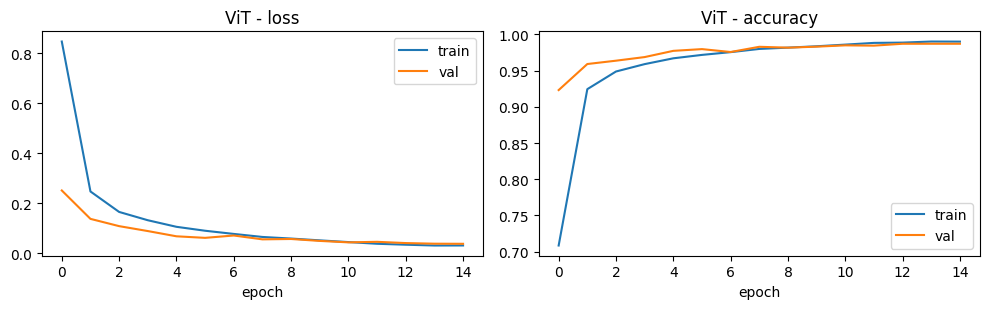

ViT | test loss 0.0399 | accuracy 98.74 % | macro-F1 0.9873
Accuracy for class 0:  99.3 %  (980 images)
Accuracy for class 1:  99.3 %  (1135 images)
Accuracy for class 2:  99.1 %  (1032 images)
Accuracy for class 3:  98.9 %  (1010 images)
Accuracy for class 4:  98.4 %  (982 images)
Accuracy for class 5:  98.3 %  (892 images)
Accuracy for class 6:  99.1 %  (958 images)
Accuracy for class 7:  98.9 %  (1028 images)
Accuracy for class 8:  98.7 %  (974 images)
Accuracy for class 9:  97.3 %  (1009 images)


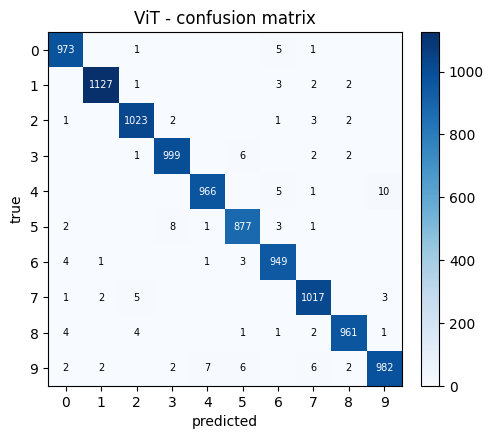

In [23]:
set_seed()
vit = make_vit().to(device)
opt_vit = torch.optim.AdamW(vit.parameters(), lr=CFG["vit_lr"], weight_decay=CFG["vit_weight_decay"])
sched_vit = torch.optim.lr_scheduler.CosineAnnealingLR(opt_vit, T_max=CFG["vit_epochs"])
hist_vit, t_vit = fit(vit, train_dl, val_dl, opt_vit, prep_mnist, CFG["vit_epochs"],
                      scheduler=sched_vit, patience=CFG["vit_patience"], name="ViT")
print(f"\nTraining time: {t_vit:.1f} s")
plot_history(hist_vit, "ViT")

res_vit, t_inf = timed_evaluate(vit, test_dl, prep_mnist)
print(f"ViT | test loss {res_vit['loss']:.4f} | accuracy {100*res_vit['acc']:.2f} % | macro-F1 {res_vit['f1']:.4f}")
log_result("ViT (from scratch)", "Transformer", vit, res_vit, t_vit, hist_vit["epochs_run"], t_inf, len(test_set))
print_per_class_accuracy(res_vit["y_true"], res_vit["y_pred"])
plot_confusion(res_vit["y_true"], res_vit["y_pred"], "ViT")

### Interpreting the ViT: where does the `[CLS]` token look?
The attention weights of the last block (averaged over heads) from the `[CLS]` token to each of the 49 patches show which part of the digit the model uses for its decision.

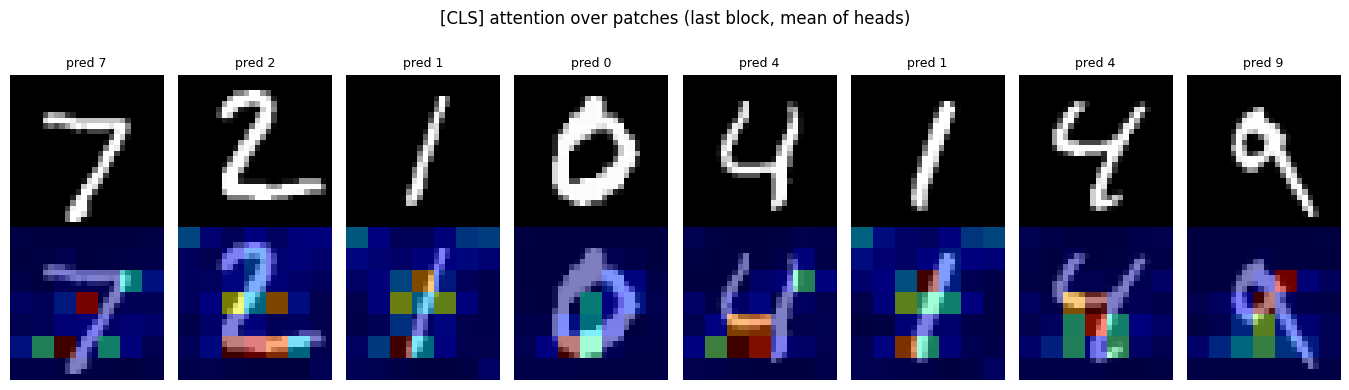

In [24]:
@torch.no_grad()
def cls_attention(model, x):
    for b in model.blocks: b.attn.store_attn = True
    model.eval(); logits = model(prep_mnist(x.to(device)))
    a = model.blocks[-1].attn.last_attn                     # (B, heads, N, N), N = 1 + n_patches
    for b in model.blocks: b.attn.store_attn = False
    side = int(math.sqrt(model.n_patches))
    return a[:, :, 0, 1:].mean(1).reshape(-1, side, side).cpu(), logits.argmax(1).cpu()

idx = list(range(8))
maps, pred = cls_attention(vit, X_test[idx])
fig, axes = plt.subplots(2, len(idx), figsize=(1.7 * len(idx), 3.8))
for c, i in enumerate(idx):
    axes[0, c].imshow(X_test[i, 0], cmap="gray"); axes[0, c].axis("off"); axes[0, c].set_title(f"pred {pred[c].item()}", fontsize=9)
    up = F.interpolate(maps[c][None, None], size=28, mode="nearest")[0, 0]
    axes[1, c].imshow(X_test[i, 0], cmap="gray"); axes[1, c].imshow(up, cmap="jet", alpha=0.5); axes[1, c].axis("off")
axes[0, 0].set_ylabel("input"); plt.suptitle("[CLS] attention over patches (last block, mean of heads)", y=1.02)
plt.tight_layout(); plt.savefig("figures/vit_attention.png", dpi=120, bbox_inches="tight"); plt.show()

## 2.2 Comparison with Part 1 and global synthesis

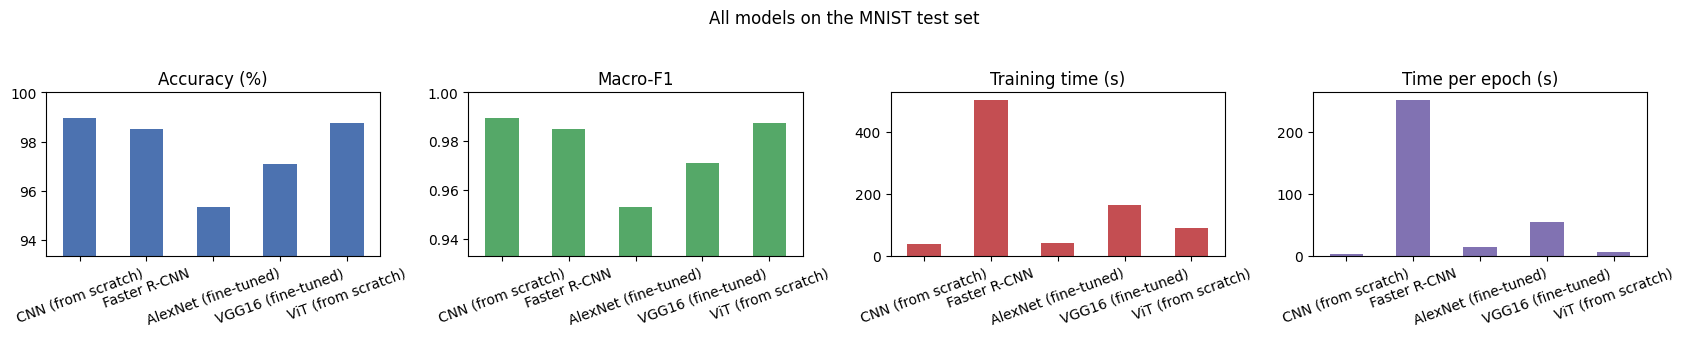

,Type,Params (M),Trainable (M),Accuracy (%),Macro-F1,Test loss,Loss type,Train time (s),Train time / epoch (s),Epochs,Inference (ms/img)
Model,,,,,,,,,,,
CNN (from scratch),Classifier,1.6259,1.6259,98.94,0.9893,0.0320,cross-entropy,38.3598,3.8360,10,0.0310
Faster R-CNN,Detector,41.3453,41.1229,98.51,0.9851,0.0441,detection (sum of 4 losses),502.4213,251.2106,2,11.5481
AlexNet (fine-tuned),Transfer learning,57.0448,54.5751,95.36,0.9528,0.1395,cross-entropy,42.0523,14.0174,3,0.0729
VGG16 (fine-tuned),Transfer learning,134.3015,119.5868,97.11,0.9709,0.0888,cross-entropy,164.5693,54.8564,3,0.4942
ViT (from scratch),Transformer,0.1358,0.1358,98.74,0.9873,0.0399,cross-entropy,88.9083,5.9272,15,0.0347


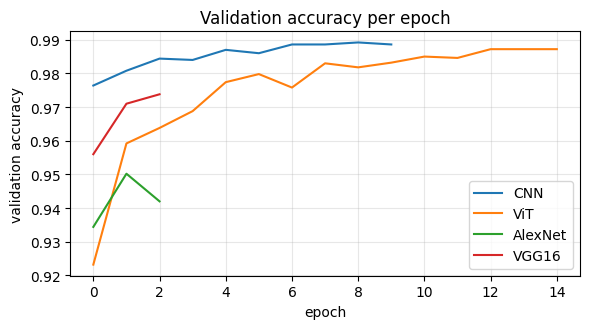

Highest accuracy : CNN (from scratch) (98.94 %)
Fastest to train : CNN (from scratch) (38 s)
Fewest parameters: ViT (from scratch) (0.14 M)


In [25]:
order = ["CNN (from scratch)", "Faster R-CNN", "AlexNet (fine-tuned)", "VGG16 (fine-tuned)", "ViT (from scratch)"]
order = [n for n in order if n in RESULTS]
df_all = compare_plot(order, "All models on the MNIST test set", "all_models")
display(df_all.round(4))
df_all.round(4).to_csv("figures/results.csv")

# training curves (validation accuracy) of the classifiers that use fit()
plt.figure(figsize=(6, 3.4))
plt.plot(hist_cnn["val_acc"], label="CNN"); plt.plot(hist_vit["val_acc"], label="ViT")
for n, (h, _) in transfer_hist.items(): plt.plot(h["val_acc"], label=n)
plt.xlabel("epoch"); plt.ylabel("validation accuracy"); plt.legend(); plt.grid(alpha=.3); plt.title("Validation accuracy per epoch")
plt.tight_layout(); plt.savefig("figures/val_acc_curves.png", dpi=120); plt.show()

best = df_all["Accuracy (%)"].idxmax(); fastest = df_all["Train time (s)"].idxmin(); smallest = df_all["Params (M)"].idxmin()
print(f"Highest accuracy : {best} ({df_all.loc[best, 'Accuracy (%)']:.2f} %)")
print(f"Fastest to train : {fastest} ({df_all.loc[fastest, 'Train time (s)']:.0f} s)")
print(f"Fewest parameters: {smallest} ({df_all.loc[smallest, 'Params (M)']:.2f} M)")